# Проект - нейросеть для предсказания калорийности блюд

Здесь выполнена "Серия 2" эксприментов - развитие экспериментов "Серии 1" `project_exp_v1`.

Основное отличие - пересмотр работы с признаками - модели янво не хватает информации.

Хронология:
1) добавление справочника калорийности ингредиентов как внешние данные
    - справочник нужно найти, обработать, сопоставить с ингредиентами и внедрить как-то в модель
    - это должно помочь модели предсказывать калорийность всего блюда
        - так как задача сужается до определения массы ингредиентов в блюде
        - а в этой части "Серия 1" дошла Mass MAE ~ 50
2) альтернативное использование признака масса блюда
3) новая архитектура совместной работы текстовых признаков и изображения - возврат к механизму внимания по-правильному


## Блок инициализации

In [2]:
# импорты
import pathlib as path
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# local scripts
import scripts.v2_attention.ingr2embed as ingr_text_embed
import scripts.v2_attention.dataset as dataset
import scripts.v2_attention.config as config
import scripts.v2_attention.models as models
import scripts.v2_attention.utils as utils

model_config = config.MealModelConfig()

SEED = model_config.SEED

# задание случайностей - seed
utils.set_random(SEED)

DATA_PATH = path.Path('data')

## Справочник калорийности

Проверка доступности подготовленного справочника калорийности продуктов

In [3]:
import scipy.sparse as sparse

ingr_cal_mapping_df = pd.read_csv(config.MealModelConfig.DATASET_EXT_KAL_MAPPING)
ingr_cal_mapping = ingr_cal_mapping_df[['food_ingr', 'energy_kcal']]

print('Ingredients kal mapping:', ingr_cal_mapping.shape)
print(ingr_cal_mapping.head(10))

Ingredients kal mapping: (197, 2)
        food_ingr  energy_kcal
0         almonds          598
1           apple           61
2      artichokes          160
3  chayote squash           19
4        bok choy           21
5       asparagus           20
6         avocado          160
7           bacon          449
8    turkey bacon          368
9      sandwiches          231


# План экспериментов

- Эксперимент 2.1 - справочник калорий (прежняя архитектеру)
    - использовать последнюю модель из "Серии 1" (эксп.9/эксп.13 - диапазон MAE 64-70)
    - добавить признаки калорийности из справочника 3-им входом во fusion-слой

- Эксперимент 2.2 - признак - масса блюда (прежняя архитектеру)
    - масса ранее не использовалась как признак (выполняла роль 2-ого таргета)
    - бастрая проверка без смены архитектуры - добавляем массу как текстовая подсказка (hint) в "предложение" с ингредиентами, без новых слоев

- Эксперимент 2.3 - кросс-внимание текста и картинок (+ справочник калорий + масса) (новая архитектеру)
    - новая архитектура внимания - полная переделка модели
    - предрассчитанные текстовые эмбеддинги каждого ингредиента-токена как отдельные признаки, вместо единого "предложения" для всего блюда
    - слияние текстовых эмбеддингов с со справочникам калорийности как дополнительный признак - расширение эмбеддинга
    - добавление массы как признак - расширение признаков

---
Если опять тупик, то попровать реализовать 2-х этапную модель - нейросеть + catboost 
- добавить табличные агрегатные признаки калорийности для каждого блюда
- количество ингредиентов
- добавить предсказание НС (или визуальные компоненты эмбеддингов картинки)
- запускать catboost поверх результатов нейросети


## Результаты (свод)

| № эксп | Лучший | Статус      | MAE   | Среда | Цель        | Комментарий 
| -      | -      | -           | -     | -     | -           | -           
| 2.1    | да (для арх. 1)     | Выполнен    | 63.23 | Goole Colab (GPU) | добавить признаки калорийности из справочника 3-им входом во fusion-слой <ul><li>использовать последнюю модель из "Серии 1" (эксп.9/эксп.13 - диапазон MAE 64-70) </ul> | достигнут предсказанный предел в 63-66 MAE: <ul><li>новый справочник калорий не сильно помог <li>проблема остается недостаточном спользовании картинки и кросс-внимании на признаках ингредиентов <li>поэтому необходим новый подход с кросс-вниманием текста и картинки</ul> 
| 2.2    | -      | Отложен (в пользу новой архитектуры) | -     | -     | используем массу блюда как текстовая подсказка (hint) <ul><li> быстрая проверка, без смены архитектуры <li> просто добавить подсказку с массой в текст и продолжить предсказывать и массу и калорийность <li> без обучения слоев backbone-моделей</ul> | -    
| 2.3    | да (арх. 2)      | Выполнен | 34.29  | VM (GPU)     | кросс-внимание текста и картинок (+ справочник калорий + масса) <ul><li> новая архитектура - полная переделка модели <li>добавление справочника калорий как признак <li>добавление массы как признак <li>предрассчитанные текстовые эмбеддинги ингредиентов (прогон DistilBERT и разовое сохранение) - ускорит обучение </ul>  | Цель достигнута - модель превзошла все ожидания
| 2.XXX  | -      | Ожидание    | -     | -     | Два этапа - сначала нейросеть, затем GBDT (Catboost) | - 

## Перезагрузка зависимостей

In [ ]:
import importlib 
import scripts.img_util as img_util

import scripts.text_utils as text_utils
import scripts.v2_attention.ingr2embed as ingr_text_embed
import scripts.v2_attention.dataset as dataset
import scripts.v2_attention.config as config
import scripts.v2_attention.models as models
import scripts.v2_attention.utils as utils

importlib.reload(dataset)
importlib.reload(utils)
importlib.reload(models)
importlib.reload(config)
importlib.reload(ingr_text_embed)
importlib.reload(img_util)
importlib.reload(text_utils)


<module 'scripts.v2_attention.text_utils' from '/home/ubuntu/projects/dle-project-sprint-4-food-calrories/scripts/v2_attention/text_utils.py'>

## Эксперимент 2.1 - добавление справочника калорийности
- использовать последнюю модель из "Серии 1" (эксп.9/эксп.13 - диапазон MAE 64-70)
- добавить признаки калорийности из справочника 3-им входом во fusion-слой
    - реализовать механизм отбора конкретных слов/токенов, через формирование полной матрицы ingr2kal_csr_matrix и дальнейшим отбором по индексу (через ingr_encoder) и суммирование для всех ингредиентов строк этой матрицы

### Эксперимент 2.1 - запуск на ВМ Colab (~ 1ч. 35 мин)

см. результаты в `project_exp_v2_colab.ipynb`

In [ ]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.v2_attention.dataset as dataset
import scripts.v2_attention.utils as utils
import scripts.v2_attention.models as models
import scripts.v2_attention.config as config

config = config.MealModelConfig()

utils.set_random(config.SEED)
log = partial(utils.log_fn, config=config)

tokenizer = AutoTokenizer.from_pretrained(config.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=config, split='train')
ingr2kal_ref_matrix, ingr_encoder = train_dataset.ingr2kal_ref_matrix, train_dataset.ingr_encoder

train_dataloader = DataLoader(dataset=train_dataset, batch_size=config.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=config, split='test', ingr2kal_ref_matrix=ingr2kal_ref_matrix, ingr_encoder=ingr_encoder)
val_dataloader = DataLoader(dataset=val_dataset, batch_size=config.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = models.MealModelNN(config=config) 

# разморозка параметров
utils.unfreeze_model_params(model, config)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору

optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': config.LR_TEXT_MODEL, 'weight_decay': config.WEIGHT_DECAY},
    {'params': [p for p in model.img_model.parameters() if p.requires_grad], 'lr': config.LR_IMG_MODEL, 'weight_decay': config.WEIGHT_DECAY},

    {'params': model.text_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.img_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.ref_k100_proj.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    
    {'params': model.norm_text.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.norm_img.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.norm_ref_k100.parameters(), 'lr': config.LR_PROJ, 'weight_decay': config.WEIGHT_DECAY},

    {'params': model.fusion.parameters(), 'lr': config.LR_FUSION, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_k_100.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_mass.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY},
    {'params': model.regression_head_kal.parameters(), 'lr': config.LR_REGRESSION_HEAD, 'weight_decay': config.WEIGHT_DECAY}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)

# for real
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи

# for debug
#warmup_steps = 75

print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {config.N_BATCH}')
print(f'n_iter = {config.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

train_loss_history = []
train_mae_history = []
train_mae_kal_100_history = []
train_mae_mass_history = []
train_mae_direct_history = []
train_time_history = []

val_loss_history = []
val_mae_history = []
val_mae_kal_100_history = []
val_mae_mass_history = []
val_mai_direct_history = []
val_time_history = []

best_metric = 1000
best_epoch = -1
for epoch in range(config.N_EPOCHS):
    train_huber_loss, train_metric_mae, train_kal_100_mae, train_mass_mae, train_direct_mae, train_time = utils.train(model=model, config=config, optimizer=optimizer, dataloader=train_dataloader, scheduler=scheduler)
    train_loss_history.append(train_huber_loss)
    train_mae_history.append(train_metric_mae)
    train_mae_kal_100_history.append(train_kal_100_mae)
    train_mae_mass_history.append(train_mass_mae)
    train_mae_direct_history.append(train_direct_mae)
    train_time_history.append(train_time)

    val_loss_huber, val_metric_mae, val_kal_100_mae, val_mass_mae, val_direct_mae, val_time = utils.validate(model=model, config=config, dataloader=val_dataloader)
    val_loss_history.append(val_loss_huber)
    val_mae_history.append(val_metric_mae)
    val_mae_kal_100_history.append(val_kal_100_mae)
    val_mae_mass_history.append(val_mass_mae)
    val_mai_direct_history.append(val_direct_mae)
    val_time_history.append(val_time)

    print(f'epoch - {epoch}: train_loss = {train_huber_loss:.2f}/{train_time:.2f} sec, train mae = {train_metric_mae:.2f}, direct mae = {train_direct_mae:.2f}, kal_100 mae = {train_kal_100_mae:.2f}, mass mae = {train_mass_mae:.2f}, \n \
            val_loss = {val_loss_huber:.2f}/{val_time:.2f} sec, val_mae = {val_metric_mae:.2f}, direct mae = {val_direct_mae:.2f}, kal_100_mae = {val_kal_100_mae:.2f}, mass_mae = {val_mass_mae:.2f}')
       
    if val_metric_mae < best_metric:
        best_metric = val_metric_mae
        best_epoch = epoch
        utils.save_checkpoint(model, config, optimizer, scheduler, epoch, best_epoch, best_metric)

    # если метрика не уменьшается в течение config.PATIENCE эпох подряд, то останавливаем обучение
    if (epoch - best_epoch) >= config.PATIENCE:
        print(f'early stopping - metric is not increasing for [{config.PATIENCE}] epochs')
        break

    if val_metric_mae < config.TARGET_METRIC:
        print(f'!! target metric reached = {config.TARGET_METRIC}, stop training')
        break

# save train logs
log_path  = path.Path(config.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

pd.DataFrame(train_loss_history, columns=['loss_huber']).to_csv(log_path / 'train_loss_history.csv', index=False)
pd.DataFrame(train_mae_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_history.csv', index=False)
pd.DataFrame(train_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_kal_100_history.csv', index=False)
pd.DataFrame(train_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_mass_history.csv', index=False)
pd.DataFrame(train_mae_direct_history, columns=['metric_mae']).to_csv(log_path / 'train_mae_direct_history.csv', index=False)
pd.DataFrame(train_time_history, columns=['time']).to_csv(log_path / 'train_time_history.csv', index=False)

pd.DataFrame(val_loss_history, columns=['loss_huber']).to_csv(log_path / 'val_loss_history.csv', index=False)
pd.DataFrame(val_mae_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_history.csv', index=False)
pd.DataFrame(val_mae_kal_100_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_kal_100_history.csv', index=False)
pd.DataFrame(val_mae_mass_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_mass_history.csv', index=False)
pd.DataFrame(val_mai_direct_history, columns=['metric_mae']).to_csv(log_path / 'val_mae_direct_history.csv', index=False)
pd.DataFrame(val_time_history, columns=['time']).to_csv(log_path / 'val_time_history.csv', index=False)

### Результат выполнения (в Colab)

```
trainable parameters = 9,587,843
warmup_steps = 146
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16
epoch - 0: train_loss = 0.71/1712.92 sec, train mae = 158.66, direct mae = 158.78, kal_100 mae = 66.10, mass mae = 117.07, 
             val_loss = 0.63/310.61 sec, val_mae = 143.04, direct mae = 137.68, kal_100_mae = 72.38, mass_mae = 100.97
checkpoint saving to - [data/model/best_model.pth]
epoch - 1: train_loss = 0.50/115.32 sec, train mae = 120.90, direct mae = 117.45, kal_100 mae = 60.60, mass mae = 92.88, 
             val_loss = 0.40/17.84 sec, val_mae = 100.84, direct mae = 96.69, kal_100_mae = 63.28, mass_mae = 70.68
checkpoint saving to - [data/model/best_model.pth]
epoch - 2: train_loss = 0.34/118.72 sec, train mae = 91.81, direct mae = 93.65, kal_100 mae = 51.57, mass mae = 68.29, 
             val_loss = 0.31/17.63 sec, val_mae = 91.01, direct mae = 87.20, kal_100_mae = 52.90, mass_mae = 63.29
checkpoint saving to - [data/model/best_model.pth]
epoch - 3: train_loss = 0.28/116.02 sec, train mae = 83.52, direct mae = 85.24, kal_100 mae = 43.64, mass mae = 64.30, 
             val_loss = 0.30/17.75 sec, val_mae = 88.05, direct mae = 85.53, kal_100_mae = 49.72, mass_mae = 60.16
checkpoint saving to - [data/model/best_model.pth]
epoch - 4: train_loss = 0.25/116.78 sec, train mae = 78.62, direct mae = 80.35, kal_100 mae = 38.18, mass mae = 60.04, 
             val_loss = 0.25/18.34 sec, val_mae = 78.56, direct mae = 77.44, kal_100_mae = 39.49, mass_mae = 63.96
checkpoint saving to - [data/model/best_model.pth]
epoch - 5: train_loss = 0.23/117.52 sec, train mae = 74.69, direct mae = 75.73, kal_100 mae = 34.40, mass mae = 59.19, 
             val_loss = 0.24/19.57 sec, val_mae = 80.80, direct mae = 77.99, kal_100_mae = 34.36, mass_mae = 64.09
epoch - 6: train_loss = 0.21/110.67 sec, train mae = 72.58, direct mae = 74.18, kal_100 mae = 32.27, mass mae = 57.70, 
             val_loss = 0.23/17.52 sec, val_mae = 76.76, direct mae = 76.05, kal_100_mae = 33.55, mass_mae = 55.14
checkpoint saving to - [data/model/best_model.pth]
epoch - 7: train_loss = 0.19/117.00 sec, train mae = 67.79, direct mae = 69.48, kal_100 mae = 30.18, mass mae = 54.01, 
             val_loss = 0.21/18.46 sec, val_mae = 74.39, direct mae = 73.94, kal_100_mae = 29.79, mass_mae = 54.26
checkpoint saving to - [data/model/best_model.pth]
epoch - 8: train_loss = 0.18/117.23 sec, train mae = 66.36, direct mae = 67.64, kal_100 mae = 28.52, mass mae = 52.92, 
             val_loss = 0.23/17.26 sec, val_mae = 76.05, direct mae = 77.28, kal_100_mae = 30.38, mass_mae = 55.77
epoch - 9: train_loss = 0.18/108.22 sec, train mae = 66.76, direct mae = 68.39, kal_100 mae = 26.75, mass mae = 53.62, 
             val_loss = 0.22/17.96 sec, val_mae = 82.74, direct mae = 79.61, kal_100_mae = 27.20, mass_mae = 60.57
epoch - 10: train_loss = 0.17/108.51 sec, train mae = 64.58, direct mae = 65.73, kal_100 mae = 26.64, mass mae = 51.31, 
             val_loss = 0.20/17.44 sec, val_mae = 74.54, direct mae = 74.19, kal_100_mae = 28.85, mass_mae = 51.68
epoch - 11: train_loss = 0.16/107.76 sec, train mae = 63.78, direct mae = 64.65, kal_100 mae = 26.33, mass mae = 50.08, 
             val_loss = 0.19/17.39 sec, val_mae = 69.54, direct mae = 69.62, kal_100_mae = 27.73, mass_mae = 50.25
checkpoint saving to - [data/model/best_model.pth]
epoch - 12: train_loss = 0.16/114.41 sec, train mae = 61.14, direct mae = 62.13, kal_100 mae = 24.54, mass mae = 49.90, 
             val_loss = 0.18/17.66 sec, val_mae = 68.75, direct mae = 68.67, kal_100_mae = 27.41, mass_mae = 49.32
checkpoint saving to - [data/model/best_model.pth]
epoch - 13: train_loss = 0.16/115.72 sec, train mae = 60.97, direct mae = 62.37, kal_100 mae = 24.93, mass mae = 50.10, 
             val_loss = 0.18/17.60 sec, val_mae = 67.84, direct mae = 68.37, kal_100_mae = 25.18, mass_mae = 49.55
checkpoint saving to - [data/model/best_model.pth]
epoch - 14: train_loss = 0.14/118.14 sec, train mae = 59.69, direct mae = 61.23, kal_100 mae = 23.78, mass mae = 47.34, 
             val_loss = 0.18/17.49 sec, val_mae = 70.12, direct mae = 69.15, kal_100_mae = 25.63, mass_mae = 50.49
epoch - 15: train_loss = 0.14/109.84 sec, train mae = 59.90, direct mae = 61.14, kal_100 mae = 23.27, mass mae = 48.05, 
             val_loss = 0.17/17.70 sec, val_mae = 66.83, direct mae = 66.54, kal_100_mae = 25.00, mass_mae = 47.75
checkpoint saving to - [data/model/best_model.pth]
epoch - 16: train_loss = 0.14/114.60 sec, train mae = 59.44, direct mae = 60.48, kal_100 mae = 22.92, mass mae = 48.41, 
             val_loss = 0.18/17.54 sec, val_mae = 69.27, direct mae = 68.79, kal_100_mae = 25.57, mass_mae = 52.03
epoch - 17: train_loss = 0.14/111.86 sec, train mae = 58.09, direct mae = 58.88, kal_100 mae = 23.34, mass mae = 47.60, 
             val_loss = 0.17/18.04 sec, val_mae = 68.05, direct mae = 66.65, kal_100_mae = 29.25, mass_mae = 47.10
epoch - 18: train_loss = 0.13/112.04 sec, train mae = 57.24, direct mae = 58.41, kal_100 mae = 23.56, mass mae = 45.63, 
             val_loss = 0.18/17.51 sec, val_mae = 68.39, direct mae = 68.34, kal_100_mae = 24.94, mass_mae = 47.58
epoch - 19: train_loss = 0.13/111.81 sec, train mae = 55.76, direct mae = 57.17, kal_100 mae = 22.46, mass mae = 46.02, 
             val_loss = 0.16/17.71 sec, val_mae = 65.31, direct mae = 65.18, kal_100_mae = 25.29, mass_mae = 46.26
checkpoint saving to - [data/model/best_model.pth]
epoch - 20: train_loss = 0.13/117.61 sec, train mae = 55.76, direct mae = 57.03, kal_100 mae = 21.22, mass mae = 44.86, 
             val_loss = 0.18/18.19 sec, val_mae = 68.96, direct mae = 68.69, kal_100_mae = 25.69, mass_mae = 47.65
epoch - 21: train_loss = 0.13/110.77 sec, train mae = 55.68, direct mae = 56.46, kal_100 mae = 21.82, mass mae = 45.50, 
             val_loss = 0.17/18.44 sec, val_mae = 67.32, direct mae = 66.79, kal_100_mae = 22.20, mass_mae = 47.76
epoch - 22: train_loss = 0.12/109.76 sec, train mae = 52.56, direct mae = 53.61, kal_100 mae = 21.48, mass mae = 43.62, 
             val_loss = 0.16/18.07 sec, val_mae = 65.13, direct mae = 64.86, kal_100_mae = 23.55, mass_mae = 44.09
checkpoint saving to - [data/model/best_model.pth]
epoch - 23: train_loss = 0.12/116.77 sec, train mae = 52.56, direct mae = 54.07, kal_100 mae = 21.45, mass mae = 43.15, 
             val_loss = 0.15/17.52 sec, val_mae = 63.86, direct mae = 63.33, kal_100_mae = 22.78, mass_mae = 45.46
checkpoint saving to - [data/model/best_model.pth]
epoch - 24: train_loss = 0.12/115.93 sec, train mae = 53.33, direct mae = 54.58, kal_100 mae = 21.31, mass mae = 44.21, 
             val_loss = 0.16/17.58 sec, val_mae = 65.35, direct mae = 65.31, kal_100_mae = 21.82, mass_mae = 45.35
epoch - 25: train_loss = 0.12/108.86 sec, train mae = 52.44, direct mae = 53.63, kal_100 mae = 20.37, mass mae = 43.25, 
             val_loss = 0.16/17.18 sec, val_mae = 66.01, direct mae = 65.30, kal_100_mae = 23.64, mass_mae = 45.86
epoch - 26: train_loss = 0.12/108.26 sec, train mae = 52.49, direct mae = 53.99, kal_100 mae = 20.55, mass mae = 42.58, 
             val_loss = 0.15/17.73 sec, val_mae = 64.19, direct mae = 62.88, kal_100_mae = 21.43, mass_mae = 44.30
epoch - 27: train_loss = 0.11/107.57 sec, train mae = 51.33, direct mae = 52.93, kal_100 mae = 20.82, mass mae = 42.32, 
             val_loss = 0.16/17.47 sec, val_mae = 63.23, direct mae = 62.96, kal_100_mae = 23.51, mass_mae = 43.49
checkpoint saving to - [data/model/best_model.pth]
epoch - 28: train_loss = 0.11/112.28 sec, train mae = 51.02, direct mae = 52.17, kal_100 mae = 20.46, mass mae = 43.22, 
             val_loss = 0.16/17.71 sec, val_mae = 64.13, direct mae = 63.95, kal_100_mae = 21.04, mass_mae = 43.76
training: 100%|██████████| 86/86 [01:48<00:00,  1.26s/it]
validation: 100%|██████████| 16/16 [00:17<00:00,  1.10s/it]
epoch - 29: train_loss = 0.11/108.17 sec, train mae = 50.45, direct mae = 51.54, kal_100 mae = 20.38, mass mae = 41.68, 
             val_loss = 0.16/17.56 sec, val_mae = 66.34, direct mae = 65.64, kal_100_mae = 21.95, mass_mae = 44.20
```

### График обучения

Text(0.5, 1.0, 'MAE')

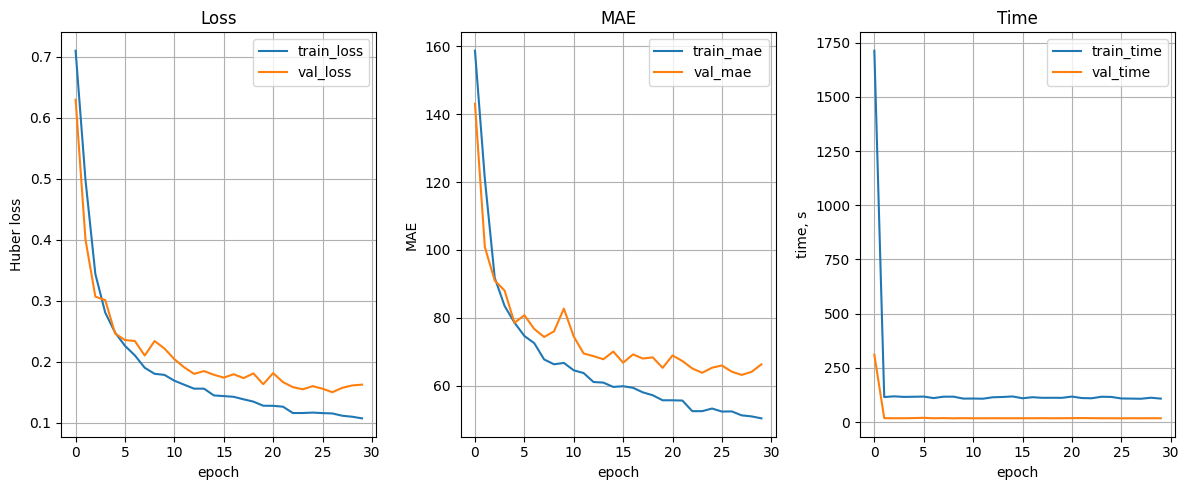

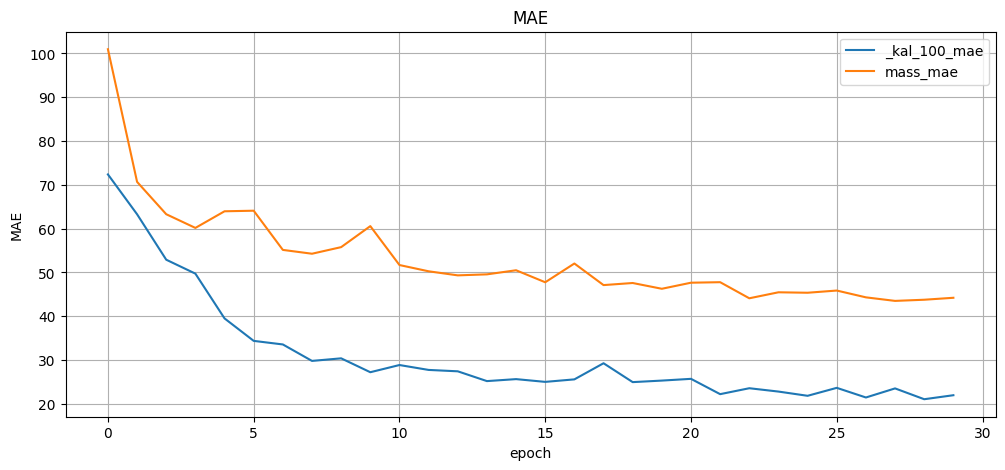

In [ ]:
import pathlib as path
import pandas as pd
import matplotlib.pyplot as plt

import scripts.v2_attention.config as cfg
import scripts.v2_attention.utils

config = cfg.MealModelConfig()

log_path  = path.Path(config.MODEL_LOG_SAVE_PATH) / 'experiments-v2' / 'exp-2.1' / 'colab'
train_loss_history = pd.read_csv(log_path /  'train_loss_history.csv')
train_mae_history = pd.read_csv(log_path / 'train_mae_history.csv')
train_time_history = pd.read_csv(log_path / 'train_time_history.csv')

val_loss_history = pd.read_csv(log_path / 'val_loss_history.csv')
val_mae_history = pd.read_csv(log_path / 'val_mae_history.csv')
val_time_history = pd.read_csv(log_path / 'val_time_history.csv')

utils.plof_train_log(train_loss_history, val_loss_history, train_mae_history, val_mae_history, train_time_history, val_time_history)

val_mae_kal_100_history = pd.read_csv(log_path / 'val_mae_kal_100_history.csv')
val_mae_mass_history = pd.read_csv(log_path / 'val_mae_mass_history.csv')

fix, axs = plt.subplots(1,1, figsize=(12,5))
ax=axs
ax.plot(val_mae_kal_100_history)
ax.plot(val_mae_mass_history)
ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('MAE');ax.legend(['_kal_100_mae', 'mass_mae'])
ax.set_title('MAE')

Достигнут предсказанный предел в 63-66 MAE
 - новый справочник калорий не сильно помог
 - проблема остается недостаточном использовании картинки и кросс-внимании на признаках ингредиентов
 - поэтому необходим новый подход с кросс-вниманием текста и картинки

# СТОП - у нас есть масса блюда 
- а сейчас логика модели построена как предсказание массы (2-ая голова), 
- а не использование ее как признак - это меняет подход

## Эксперимент 2.2 - используем массу как число в тексте как подсказка (не выполнен)
- не использована масса блюда как признак 
    - быстрая проверка - не меняю архитектуру 
    - просто добавить подсказку с массой в текст и продолжить предсказывать и массу и калорийность

In [ ]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
import scripts.v2_attention.dataset as dataset
import scripts.v2_attention.utils as utils
import scripts.v2_attention.models as models
import scripts.v2_attention.config as config

cfg = config.MealModelConfig()

utils.set_random(cfg.SEED)
log = partial(utils.log_fn, config=cfg)

tokenizer = AutoTokenizer.from_pretrained(cfg.TEXT_MODEL_NAME)

train_dataset = dataset.MealDataset(model_config=cfg, split='train')
ingr2kal_ref_matrix, ingr_encoder = train_dataset.ingr2kal_ref_matrix, train_dataset.ingr_encoder

train_dataloader = DataLoader(dataset=train_dataset, batch_size=cfg.N_BATCH, shuffle=True, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

val_dataset = dataset.MealDataset(model_config=cfg, split='test', ingr2kal_ref_matrix=ingr2kal_ref_matrix, ingr_encoder=ingr_encoder)
val_dataloader = DataLoader(dataset=val_dataset, batch_size=cfg.N_BATCH, shuffle=False, collate_fn=partial(dataset.collate_fn, tokenizer=tokenizer))

model = models.MealModelNN(config=cfg)

# разморозка параметров
utils.unfreeze_model_params(model, cfg)

train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
print(f'trainable parameters = {train_params:,d}')

# подключаем обучаемые (активные) параметры к оптимизатору

optimizer = torch.optim.AdamW([
    {'params': [p for p in model.text_model.parameters() if p.requires_grad], 'lr': cfg.LR_TEXT_MODEL, 'weight_decay': cfg.WEIGHT_DECAY},
    {'params': [p for p in model.img_model.parameters() if p.requires_grad], 'lr': cfg.LR_IMG_MODEL, 'weight_decay': cfg.WEIGHT_DECAY},

    {'params': model.text_proj.parameters(), 'lr': cfg.LR_PROJ, 'weight_decay': cfg.WEIGHT_DECAY},
    {'params': model.img_proj.parameters(), 'lr': cfg.LR_PROJ, 'weight_decay': cfg.WEIGHT_DECAY},
    {'params': model.ref_k100_proj.parameters(), 'lr': cfg.LR_PROJ, 'weight_decay': cfg.WEIGHT_DECAY},

    {'params': model.norm_text.parameters(), 'lr': cfg.LR_PROJ, 'weight_decay': cfg.WEIGHT_DECAY},
    {'params': model.norm_img.parameters(), 'lr': cfg.LR_PROJ, 'weight_decay': cfg.WEIGHT_DECAY},
    {'params': model.norm_ref_k100.parameters(), 'lr': cfg.LR_PROJ, 'weight_decay': cfg.WEIGHT_DECAY},

    {'params': model.fusion.parameters(), 'lr': cfg.LR_FUSION, 'weight_decay': cfg.WEIGHT_DECAY},
    {'params': model.regression_head_k_100.parameters(), 'lr': cfg.LR_REGRESSION_HEAD, 'weight_decay': cfg.WEIGHT_DECAY},
    {'params': model.regression_head_mass.parameters(), 'lr': cfg.LR_REGRESSION_HEAD, 'weight_decay': cfg.WEIGHT_DECAY},
    {'params': model.regression_head_kal.parameters(), 'lr': cfg.LR_REGRESSION_HEAD, 'weight_decay': cfg.WEIGHT_DECAY}
])

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# - прогрев learning rate warmup
iters_per_epoch = len(train_dataloader)

# for real
warmup_steps = int(1.7 * iters_per_epoch)   # ≈1.7 эпохи

# for debug
#warmup_steps = 75

print(f'warmup_steps = {warmup_steps}')
scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda step: min(1.0, step / warmup_steps)  # 150 шагов ≈ 1.7 эпохи при BATCH=32
)

print(f'batch size = {cfg.N_BATCH}')
print(f'n_iter = {cfg.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

# Metric schema: (csv column name, filename stem, log label)
# Order MUST match what utils.train / utils.validate return.
OUT_SPEC = [
    ("loss",    "loss_huber"),
    ("mae",     "metric_mae"),
    ("kal_100", "metric_mae"),
    ("mass",    "metric_mae"),
    ("direct",  "metric_mae"),
    ("time",    "time")
]
OUT_NAMES = [name for name, _ in OUT_SPEC]

train_hist = {k: [] for k in OUT_NAMES}
val_hist   = {k: [] for k in OUT_NAMES}

def record_history(hist, values):
    if len(values) != len(OUT_NAMES):
        raise ValueError(
            f"expected {len(OUT_NAMES)} outputs {OUT_NAMES}, got {len(values)}"
        )
    for name, v in zip(OUT_NAMES, values):
        hist[name].append(v)

def log_out(split, values):
    d = dict(zip(OUT_NAMES, values))
    return (f"{split}: loss = {d['loss']:.2f}/{d['time']:.2f} sec, "
            f"mae = {d['mae']:.2f}, direct mae = {d['direct']:.2f}, "
            f"kal_100 mae = {d['kal_100']:.2f}, mass mae = {d['mass']:.2f}")

best_metric = float("inf")
best_epoch  = -1

for epoch in range(cfg.N_EPOCHS):
    train_out = utils.train(model=model, config=cfg, optimizer=optimizer,
                            dataloader=train_dataloader, scheduler=scheduler)
    record_history(train_hist, train_out)

    val_out = utils.validate(model=model, config=cfg, dataloader=val_dataloader)
    record_history(val_hist, val_out)

    val_metric_mae = val_out[OUT_NAMES.index("mae")]
    print(f"epoch - {epoch}: {log_out('train', train_out)}")
    print(f"          {log_out('val', val_out)}")

    if val_metric_mae < best_metric:
        best_metric, best_epoch = val_metric_mae, epoch
        utils.save_checkpoint(model, cfg, optimizer, scheduler,
                              epoch, best_epoch, best_metric)

    if epoch - best_epoch >= cfg.PATIENCE:
        print(f"early stopping - metric is not improving for [{cfg.PATIENCE}] epochs")
        break
    if val_metric_mae < cfg.TARGET_METRIC:
        print(f"!! target metric reached = {cfg.TARGET_METRIC}, stop training")
        break

# save train logs

log_path = path.Path(cfg.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

def save_histories(histories):
    """
    file name format: <split>_<stem>_history.csv
    """
    for split, hist in histories:
        for name, col_name in OUT_SPEC:
            df_path = f"{split}_{name}_history.csv"
            pd.DataFrame({col_name: hist[name]}).to_csv(log_path / df_path, index=False)

save_histories([("train", train_hist), ("val", val_hist)])

### Выполнение - ожидание ВМ

## Эксперимент 2.3 - кросс-внимание текста и картинок 
Изменения:
    - новая архитектура внимания - полная переделка модели
    - предрассчитанные текстовые эмбеддинги каждого ингредиента-токена как отдельные признаки, вместо единого "предложения" для всего блюда
    - слияние текстовых эмбеддингов с со справочникам калорийности как дополнительный признак - расширение эмбеддинга
    - добавление массы как признак - расширение признаков

Почему не сработала первая версия внимания:
- использование единственного CLS-токена означает то, что seq_len в механизме внимания равен 1
    - это приводит к простому усреднению признаков картинки (Global Attention Pooling), вместо самого механизма внимания
    - модель не может сопоставить конкретный ингредиент с его областью на фото
    - так было реализовано в Эксп. 0, и вся дальнейшая работа строилась вместо внимания на fusion (конкатенации) эмбеддингов текста и картинки
        - однако fusion себя исчерпал (хоть модель и сходиться медленно в сторону 60 MAE на test, на train модель смогла достигнуть 50 MAE, при этом переобучение начало усиливаться и далее нужна дополнительная регуляризация или аугментация)

### Новая архитектура - полная переделка модели
- кросс-модальное внимание текстовых токенов-ингредиентов и эмбеддингов картики

- в текст подаем только ингредиенты
    - если без fine-tune, то эмбеддинги можно заранее рассчитать и подавать как готовые признаки в модель - это может ускорить вычисления ~ в 5 раз

- дополнительные физические признаки 
    - признаки ингредиентов - prop_emb (справочная калорийность, опционально - плотность, БЖУ (зависит от доступности справочника))
        - объединение с текстовыми эмбедингами ингредиентов (concat)
    - масса блюда  
        - это просто число (не вектор)
        - чтобы модель могла учить нелинейные зависимости от размеры порции, пропускаем через блок с нелинейностью (Linear(1, 64) + GELU + Linear(64, 256))

- признаки картинки необходимо использовать до усреднения (global average pooling), чтобы иметь набор пространственных признаков
    - использовать пространственную карту признаков на выходном слое до пулинга [Batch, img_feat_dim=1280, 14, 14]
    - развернуть признаки в набор "патчей" по каждому "пикселю" финальной карты - форма [Batch, 196=14x14, img_feat_dim]
        - так получится последовательность из 196 векторов, каждый из которых отвечает за свою область на картинке
        - получаем ответ - что картинка содержит в этом патче размерностью img_feat_dim

- все проекции выполняем через слой нелинейности, а не как простой nn.Linear
    - связку (nn.Linear + nn.Gelu + nn.LayerNorm/nn.BatchNorm2D + nn.Dropout)
    - это позволит модели извлекать сложные зависимости, а не просто комбинировать линейные признаки
    - нормализация перед слоем внимания

- механизм кросс-внимания
    - кросс-внимание реализуем по каждому токену текста (ингредиенту) со всеми признаками картинки
    - Query - [Batch, S, D_model] - ингредиенты (с учетом маски, для выравнивания длины в батче - названия блюд имеют разные длины)
        - проекции эмбеддингов признаков суммируются с проекцией массы, чтобы не менять размерность S (seq_len - длина цепочки ингредиентов) и не нарушить тем самым вычисление долей
        - каждый ингредиент таким способом "получит знание" о массе блюда
    - Key, Value - [Batch, 196, 960] - 196 пространственных регионов изображения
    - в результате, каждый токен (ингредиент) просканирует все области изображения и извлечет информацию о размере, и том как он выглядит

- ffn (feed-forward) после кросс-внимания
    - это обязательная 2-ая половина "блока внимания"
    - перерабатывает собранную информацию от внимания индивидуально для каждого признака
    - выход внимания суммируем с исходным текстовыми признаками (query), чтобы передать без потерь дальше, по аналогии с residual connection
    - вход нормализуется 
    - внутренний слой расширяется, добавляется нелинейность и сужение обратно

- выход (голова)
    - выход состоит из 2-х компонентов
        - предсказание доли каждого элемента на блюде - p_i (линейный слой + softmax)
        - предсказание кал/100г каждого элемента - k_100_i
            - так как у нас задана справочная калорийность по неоднозначному соответсвию, реальная калорийность в блюдах может отличаться
            - необходимо дать модели возможность дообучать отклонение в калорийности, например с учетом наличия способа приготовления, извлекаемого из изображения
    - считаем итоговые калории
        - pred_kal = M_total x Sum(p_i * k_100_i) / 100

### Аспекты реализации

- как извлечь текстовые эмбеддинги по конкретным ингредиентам на выходе из DistilBERT (если этого не сделать потеряется 1-1 связь всех признаков и вычислений долей в softmax)
    - это делается предварительно по каждому токену до подачи в модель
    - прогоняем через DistilBERT каждый ингредиент
        - опционально усиливаем фразу пищевым контектом (на случай слов омонимов из других областей):
            - например, ингредиент: "olive oil"
            - подаем текст: "food ingredient: olive oil" 
        - выполняем mean pooling на выходе по всем субтокенам, чтобы получить вектор [1, text_dim]
            - при этом надо удалить спец-токены CLS, SEP, чтобы они не размывали значения
    - таким образом для каждого ингредиента получаем вектор [1, text_dim]
    - в forward подаем тензор [Batch, K_max, text_dim], где K_max - max количество ингредиентов в блюде для данного батча
    
- вычисление результата
    - доли ингредиентов
        - через nn.Linear(D_model, 1) - получаем K-логитов z1,..,zk - для каждого ингредиента
        - маскируем паддинг-ингредиенты значением -inf, чтобы учесть выравнивание текста до max длины в батче (collate_fn) 
        - применяем Softmax для получения долей p1,...,pk

- подготовка списка эмбеддингов и справочника калорийности ингредиентов 
    - примеры с нулевой массой, калорийностью - "plate only" 
        - удалить, иначе деление на ноль привет к взырвному росту/ошибке
        - как опция (в будущем) - добавить обработку (построцессинг) в обход нейросети, что target=0
    - "deprecated" ингредиенты
        - для простоты удалить блюда с их участием, так как они будут мешать определять точный состав блюда
    - если продукт есть на test, но его нет на train - по итогам анализа такие есть (2 ингредиента и 6 блюд с ними) 
        - текстовые эмбеддинги будут сформированы для всех, поэтому "незнакомый" ингредиент будет скорее всего на что-нибудь похож из train
        - справочная калорийность будет доступна
        - таким образом модель будет пытаться вычислить для него предсказание
        - можно оставить пока и не удалять такие примеры       
    - таким образом - справочник ингредиентов - полный список всех ингредиентов на train/test с фильтрацией "plate only" и "deprecated"

- параметры оптимизатора
    - используется прогрев (warmup) `learning rate` 
        - первые 1.5 эпохи lr плавно возрастает до заданного значения (LinearLR)
        - на остальных эпохах до конца используется CosineAnnealingLR - который плавно затухает почти до нуля
        - таким образом шаг корректируется плавно на всех этапах

### План реализации

```
1. [+] [Новое] Текстовая подготовка ингредиентов 
    + подготовить эмбеддинги ингредиентов на DistilBert модели
    + подготовить кодировщик name -> id + учет элемента для паддинга
    + сохранить в файл для быстрого извлечения в датасете

2. [+] Справочник калорийности
    + реализация упростилась - достаточно извлечь признаки по каждому ингредиенту в датасете
    
3. [+] Датасет
    + загрузка текстовых эмбеддингов ингредиентов
    + загрузка признаков ингредиентов - справчоная калорийность (пока без БЖУ)
    + загрузка массы блюда
    + загрузка и аугментация изображений

4. [+] Загрузчик данных по батчам
    + реализация collate_fn для выравнивания длины размерности ингредиентов до K_max с помощью padding

5. [+] Модель
    + слиение и проекция текстовых эмбеддингов с признаками 
    + добавление проекции массы
    + генерация и переупорядочивание признаков изображения
    + кросс-внимание признаков текста и изображения
    + обработка результатов кросс-внимания (ffn)
    + слой дообучения и поправки калорийности ингредиентов k_100
    + выходы
        + доли ингредиентов
        + k_100 ингредиентов
        + общая калорийность

6. [+] Общий процесс обучения
    + проверить warmup для шага обучения (цель неразрушение backbone моделей на старте обучения - уменьшение шага для них)
    + проверить параметры оптимизатора
```

In [ ]:
# предварительно формируем текстовые эмбеддинги ингредиентов

tokenizer = AutoTokenizer.from_pretrained(cfg.TEXT_MODEL_NAME)
text_model = AutoModel.from_pretrained(cfg.TEXT_MODEL_NAME)

ingr_text_embed.make_ingr_embeddings(tokenizer, text_model, cfg.DATASET_PATH)

ingrs: (197,) ['almonds' 'apple' 'artichokes' 'arugula' 'asparagus']
ingr_encoder: [('<PAD>', 0), ('almonds', 1), ('apple', 2), ('artichokes', 3), ('arugula', 4)]
text_embs: torch.Size([197, 768]) save to file:  data/preprocess/text_emb.pt


In [ ]:
# проверяем, что эмбеддинги корректно извлекаются для ингредиентов после токенизации

import scripts.text_utils as text_utils
import scripts.v2_attention.config as config

cfg = config.MealModelConfig()

df = pd.read_csv(path.Path(model_config.DATASET_PATH))

# загрузка подготовленных эмбеддингов
text_embs_loaded = torch.load(cfg.TEXT_EMBED_PATH)
ingr_encoder = text_embs_loaded['ingr_encoder']
all_ingr_embs = text_embs_loaded['text_embs']   

# тестовое блюдо для проверки
index = 290
item = df.iloc[index]
dish_id = item['dish_id']
print(item)

# список сырых ингредиентов
raw_ingr = item['ingr_name']
ingr_list = text_utils.preprocess_ingredients(raw_ingr)

# список эмбеддингов ингредиентов для данного блюда
ingr_embs = torch.stack([all_ingr_embs[ingr_encoder[ingr]] for ingr in ingr_list])
ingr_embs.shape, ingr_embs

dish_id                                           dish_1558631932
total_calories                                         214.931992
total_mass                                                  355.0
split                                                       train
ing_count                                                     3.0
ingr_id                                      [54.0, 205.0, 471.0]
ingr_name         ['apple', 'corn on the cob', 'cherry tomatoes']
Name: 290, dtype: object


(torch.Size([3, 768]),
 tensor([[-0.3296,  0.0626, -0.2114,  ..., -0.0594, -0.0318, -0.4640],
         [-0.1696, -0.0154, -0.1767,  ..., -0.0709,  0.0514, -0.0601],
         [-0.1944, -0.0993, -0.1496,  ..., -0.1458,  0.0577, -0.3791]],
        grad_fn=<StackBackward0>))

### Запуск обучения

In [ ]:
import numpy as np
import pandas as pd
import pathlib as path
from functools import partial
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel

# local scripts
# v2 - новая архитектура
import scripts.v2_attention.config as config
import scripts.v2_attention.ingr2embed as ingr_text_embed
import scripts.v2_attention.dataset as dataset
import scripts.v2_attention.models as models
import scripts.v2_attention.utils as utils

cfg = config.MealModelConfig()
utils.set_random(cfg.SEED)
log = partial(utils.log_fn, config=cfg)

tokenizer = AutoTokenizer.from_pretrained(cfg.TEXT_MODEL_NAME)
text_model = AutoModel.from_pretrained(cfg.TEXT_MODEL_NAME)

# 1 - подготовка текстовых эмбеддингов ингредиентов
# выполнить один раз достаточно - уже выполнено выше
# ingr_text_embed.make_ingr_embeddings(tokenizer, text_model, cfg.DATASET_PATH)

# 2- датасеты и загрузчик
train_dataset = dataset.MealDataset(model_config=cfg, split='train')
train_dataloader = DataLoader(dataset=train_dataset, batch_size=cfg.N_BATCH, shuffle=True, collate_fn=dataset.collate_fn)

val_dataset = dataset.MealDataset(model_config=cfg, split='test')
val_dataloader = DataLoader(dataset=val_dataset, batch_size=cfg.N_BATCH, shuffle=False, collate_fn=dataset.collate_fn)

# 3 - подготовка модели и оптимизатора
model = models.MealMode_WithAttention_NN(config=cfg, freeze_backbone=True)
models.unfreeze_model_params(model, cfg)

# подключаем обучаемые (активные) параметры к оптимизатору
optimizer = utils.get_optimizer(model, backbone_lr=cfg.LR_IMG_MODEL, head_lr=cfg.LR_HEAD, k_100_ref_lr=cfg.LR_K_100_REF, weight_decay=cfg.WEIGHT_DECAY)

# проверка, что все активные параметры добавлены в оптимизатор
utils.optimizer_params_sanity_check(model, optimizer)

# прогрев learning rate warmup
num_epochs = cfg.N_EPOCHS
iters_per_epoch = len(train_dataloader)
total_steps = num_epochs * iters_per_epoch
warmup_steps = int(1.5 * iters_per_epoch)  # ~1.5 эпохи плавного прогрева

# 1. Фаза прогрева: lr линейно растет от 1% до 100% базового значения
warmup_scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.01, end_factor=1.0, total_iters=warmup_steps)
# 2. Фаза основного обучения: плавное косинусное затухание до почти нуля
cosine_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps-warmup_steps, eta_min=1e-6) 
# Объединяем оба шедулера в один
scheduler = torch.optim.lr_scheduler.SequentialLR(optimizer, schedulers=[warmup_scheduler, cosine_scheduler], milestones=[warmup_steps])

print(f'batch size = {cfg.N_BATCH}')
print(f'n_iter = {cfg.N_ITER}')
print(f'train iterations/batch = {len(train_dataloader)}')
print(f'val iterations/batch = {len(val_dataloader)}')

# Подготовка структуры для логирование результатов (много однообразных метрик, чтобы убрать boilerplate код)
# порядок соответсвует выходу из utils.train()/validate().
OUT_SPEC = [
    ("loss",                     "loss_huber"),
    ("mae",                      "metric_mae"),
    ("kal_100",                  "metric_mae"),
    ("mass",                     "gram"),
    ("k_100_delta_global",       "kal"),
    ("k_100_delta_img",          "kal"),
    ("time",                     "time")
]
OUT_NAMES = [name for name, _ in OUT_SPEC]

train_hist = {k: [] for k in OUT_NAMES}
val_hist   = {k: [] for k in OUT_NAMES}

def record_history(hist, values):
    if len(values) != len(OUT_NAMES):
        raise ValueError(
            f"expected {len(OUT_NAMES)} outputs {OUT_NAMES}, got {len(values)}"
        )
    for name, v in zip(OUT_NAMES, values):
        hist[name].append(v)

def log_out(split, values):
    d = dict(zip(OUT_NAMES, values))
    return (f"{split}: loss = {d['loss']:.2f}/{d['time']:.2f} sec, "
            f"mae = {d['mae']:.2f}, kal_100 mae = {d['kal_100']:.2f}, "
            f"k_100_delta_global = {d['k_100_delta_global']:.2f}, k_100_delta_img = {d['k_100_delta_img']:.2f}")

def show_trainable_params(model: nn.Module):
    train_params = np.sum([p.numel() for p in model.parameters() if p.requires_grad])
    print(f'trainable parameters = {train_params:,d}')

unfreeze_epoch = 3
best_metric = float("inf")
best_epoch  = -1

show_trainable_params(model)

for epoch in range(cfg.N_EPOCHS):
    
    train_out = utils.train(model=model, config=cfg, optimizer=optimizer,
                            dataloader=train_dataloader, scheduler=scheduler)
    record_history(train_hist, train_out)

    val_out = utils.validate(model=model, config=cfg, dataloader=val_dataloader)
    record_history(val_hist, val_out)

    val_metric_mae = val_out[OUT_NAMES.index("mae")]
    print(f"epoch - {epoch}: {log_out('train', train_out)}")
    print(f"          {log_out('val', val_out)}")

    if val_metric_mae < best_metric:
        best_metric, best_epoch = val_metric_mae, epoch
        utils.save_checkpoint(model, cfg, optimizer, scheduler,
                              epoch, best_epoch, best_metric)

    if epoch - best_epoch >= cfg.PATIENCE:
        print(f"early stopping - metric is not improving for [{cfg.PATIENCE}] epochs")
        break
    if val_metric_mae < cfg.TARGET_METRIC:
        print(f"!! target metric reached = {cfg.TARGET_METRIC}, stop training")
        break

# save train logs

log_path = path.Path(cfg.MODEL_LOG_SAVE_PATH)
log_path.mkdir(exist_ok=True)

def save_histories(histories):
    """
    file name format: <split>_<stem>_history.csv
    """
    for split, hist in histories:
        for name, col_name in OUT_SPEC:
            df_path = f"{split}_{name}_history.csv"
            pd.DataFrame({col_name: hist[name]}).to_csv(log_path / df_path, index=False)

save_histories([("train", train_hist), ("val", val_hist)])

ingrs: (197,) ['almonds' 'apple' 'artichokes' 'arugula' 'asparagus']
ingr_encoder: len = 198 [('<PAD>', 0), ('almonds', 1), ('apple', 2), ('artichokes', 3), ('arugula', 4)]
text_embs: torch.Size([198, 768]) save to file:  data/preprocess


model.safetensors:   0%|          | 0.00/131M [00:00<?, ?B/s]

mobilenetv4_conv_aa_large - parameter id unfreezed: blocks.4.0.conv.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: blocks.4.0.bn1.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: blocks.4.0.bn1.bias
mobilenetv4_conv_aa_large - parameter id unfreezed: conv_head.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: norm_head.weight
mobilenetv4_conv_aa_large - parameter id unfreezed: norm_head.bias
batch size = 32
n_iter = -1
train iterations/batch = 86
val iterations/batch = 16
trainable parameters = 2,697,800


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
validation: 100%|██████████| 16/16 [00:19<00:00,  1.19s/it]


epoch - 0: train: loss = 107.26/122.18 sec, mae = 95.42, kal_100 mae = 42.92, k_100_delta_global = 0.05, k_100_delta_img = 0.47
          val: loss = 72.59/19.04 sec, mae = 64.74, kal_100 mae = 32.32, k_100_delta_global = 0.09, k_100_delta_img = 2.60
checkpoint saving to - [data/model/best_model.pth]


training:  49%|████▉     | 42/86 [00:51<00:53,  1.22s/it]/home/ubuntu/projects/dle-project-sprint-4-food-calrories/.venv/lib/python3.10/site-packages/torch/optim/lr_scheduler.py:198: UserWarning: The epoch parameter in `scheduler.step()` was not necessary and is being deprecated where possible. Please use `scheduler.step()` to step the scheduler. During the deprecation, if epoch is different from None, the closed form is used instead of the new chainable form, where available. Please open an issue if you are unable to replicate your use case: https://github.com/pytorch/pytorch/issues/new/choose.
  warnings.warn(EPOCH_DEPRECATION_WARNING, UserWarning)
validation: 100%|██████████| 16/16 [00:17<00:00,  1.07s/it]


... (53 outputs left out)

validation: 100%|██████████| 16/16 [00:17<00:00,  1.07s/it]


epoch - 28: train: loss = 31.56/106.00 sec, mae = 32.02, kal_100 mae = 14.87, k_100_delta_global = 1.69, k_100_delta_img = -0.02
          val: loss = 34.74/17.20 sec, mae = 34.29, kal_100 mae = 16.28, k_100_delta_global = 1.48, k_100_delta_img = -0.03
checkpoint saving to - [data/model/best_model.pth]


validation: 100%|██████████| 16/16 [00:17<00:00,  1.08s/it]

epoch - 29: train: loss = 31.58/106.14 sec, mae = 32.03, kal_100 mae = 14.82, k_100_delta_global = 1.67, k_100_delta_img = -0.02
          val: loss = 34.82/17.25 sec, mae = 34.38, kal_100 mae = 16.37, k_100_delta_global = 1.48, k_100_delta_img = -0.02


### График обучения

Text(0.5, 1.0, 'MAE')

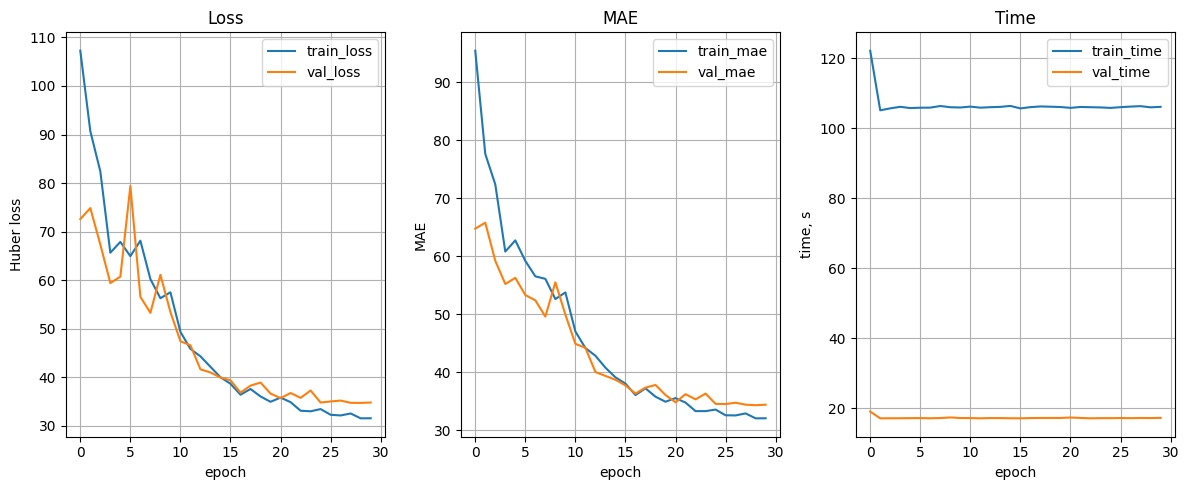

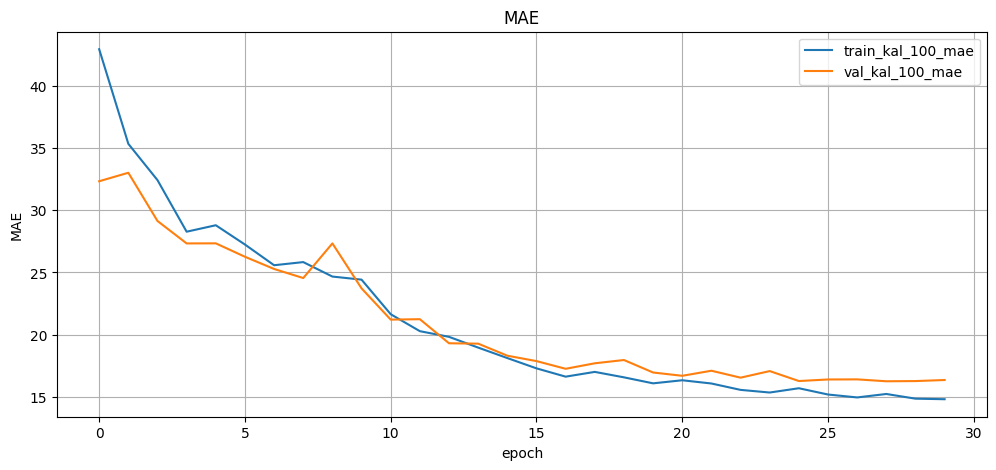

In [ ]:
import pathlib as path
import pandas as pd
import matplotlib.pyplot as plt

import scripts.v2_attention.config as cfg
import scripts.v2_attention.utils

config = cfg.MealModelConfig()

log_path  = path.Path(config.MODEL_LOG_SAVE_PATH) / 'exp-2.3'
train_loss_history = pd.read_csv(log_path /  'train_loss_history.csv')
train_mae_history = pd.read_csv(log_path / 'train_mae_history.csv')
train_time_history = pd.read_csv(log_path / 'train_time_history.csv')

val_loss_history = pd.read_csv(log_path / 'val_loss_history.csv')
val_mae_history = pd.read_csv(log_path / 'val_mae_history.csv')
val_time_history = pd.read_csv(log_path / 'val_time_history.csv')

utils.plof_train_log(train_loss_history, val_loss_history, train_mae_history, val_mae_history, train_time_history, val_time_history)

train_kal_100_history = pd.read_csv(log_path / 'train_kal_100_history.csv')
val_kal_100_history = pd.read_csv(log_path / 'val_kal_100_history.csv')

fix, axs = plt.subplots(1,1, figsize=(12,5))
ax=axs
ax.plot(train_kal_100_history)
ax.plot(val_kal_100_history)
ax.grid();ax.set_xlabel('epoch');ax.set_ylabel('MAE');ax.legend(['train_kal_100_mae', 'val_kal_100_mae'])
ax.set_title('MAE')

Результат - цель MAE < 50 достигнута - mae = 34.29:
```
epoch - 28: 
train: loss = 31.56/106.00 sec, mae = 32.02, kal_100 mae = 14.87, k_100_delta_global = 1.69, k_100_delta_img = -0.02
  val: loss = 34.74/17.20 sec, mae = 34.29, kal_100 mae = 16.28, k_100_delta_global = 1.48, k_100_delta_img = -0.03
```